In [36]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers, models, regularizers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [37]:
(X_train, y_train), (X_test, y_test) = (keras.datasets.mnist.load_data())

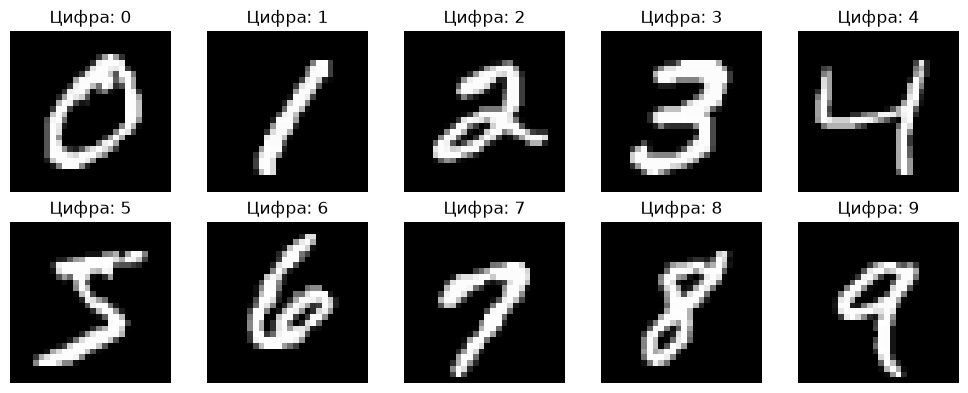

In [38]:
fig, axes = plt.subplots(2,5,figsize=(10,4))

for i in range(10):
    j = 0
    while i != y_train[j]:
        j += 1
    axes.flat[i].imshow(X_train[j], cmap="gray")
    axes.flat[i].set_title(f"Цифра: {y_train[j]}")
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [39]:
model_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Flatten(),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,346 (3.14 MB)

 Trainable params: 822,346 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model_cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

In [41]:
early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_cnn = model_cnn.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    callbacks=[early_stop_cnn]
)

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - loss: 0.9237 - sparse_categorical_accuracy: 0.8871 - val_loss: 0.1697 - val_sparse_categorical_accuracy: 0.9815
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - loss: 0.1933 - sparse_categorical_accuracy: 0.9714 - val_loss: 0.1488 - val_sparse_categorical_accuracy: 0.9842
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - loss: 0.1546 - sparse_categorical_accuracy: 0.9778 - val_loss: 0.1347 - val_sparse_categorical_accuracy: 0.9877
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - loss: 0.1360 - sparse_categorical_accuracy: 0.9807 - val_loss: 0.1225 - val_sparse_categorical_accuracy: 0.9882
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 45ms/step - loss: 0.1243 - sparse_categorical_accuracy: 0.9819 - val_loss: 0.1196 - val_sparse_categorical_accuracy: 0.9855
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - loss: 0.1157 - sparse_categorical_accuracy: 0.9832 - val_loss: 0.1099 - val_sparse_categorical_acc

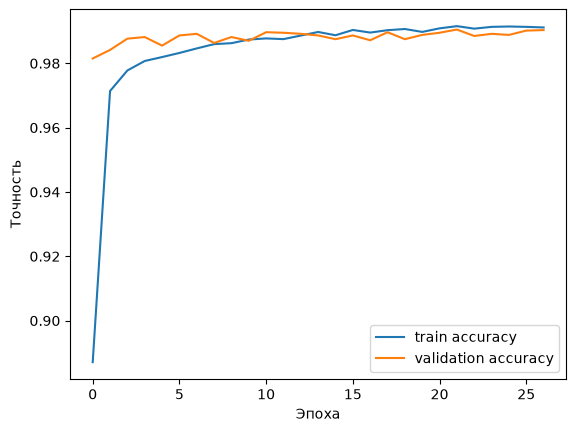

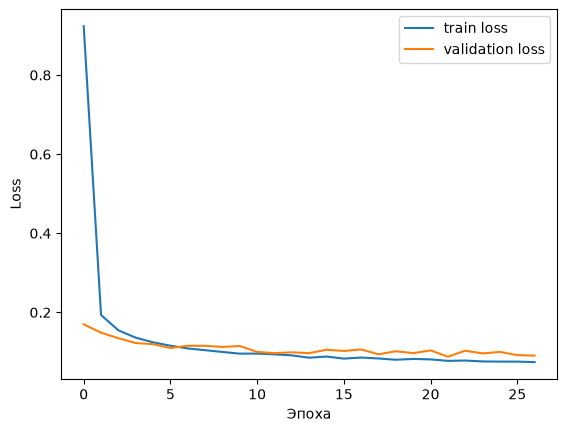

In [42]:
plt.plot(history_cnn.history['sparse_categorical_accuracy'], label='train accuracy')
plt.plot(history_cnn.history['val_sparse_categorical_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.show()

plt.plot(history_cnn.history['loss'], label='train loss')
plt.plot(history_cnn.history['val_loss'], label='validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [43]:
y_pred = np.argmax(model_cnn.predict(X_test), axis=1)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[[ 973    3    1    0    0    0    1    2    0    0]
 [   0 1132    0    1    0    0    0    2    0    0]
 [   0    0 1015    0    2    0    2   11    2    0]
 [   0    0    3  990    0    9    0    5    2    1]
 [   0    0    0    0  971    0    0    0    2    9]
 [   1    0    0    3    1  879    1    2    1    4]
 [   4    4    0    0    2    1  944    0    3    0]
 [   1    1    2    0    0    0    0 1022    0    2]
 [   4    1    1    0    1    0    1    0  964    2]
 [   0    2    1    0    5    3    0    4    3  991]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.98      0.99      1032
           3       1.00      0.98      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99      